# The alignment window

This notebook runs one alignment script and shows, while it runs, what the microscope does
(requirement D6, example E11). It shows three things together:

- the column of the fitted model of notebook 2, at the lens and deflector values that the
  microscope has now, with a fan of rays from the source (TemGym's legacy plot);
- the SightX frame, with the beam where the fitted model predicts it (a circle of its rms
  radius);
- the script, and the last lines that it printed.

The script runs as it is, with no code added for the window (requirement D7), in the notebook's
own thread: an interrupt (the stop button, Ctrl-C) reaches the script, which then sets the
microscope back as it always does. The view draws from a second thread. It reads the values and
takes its frames through the script's own jemwrap monitor, which spaces every call to the
microscope, so the same window works on the simulated and on the real NEOARM. It reads only:
jemwrap's read and frame calls change nothing. The view runs a few seconds behind the script,
and its reads slow the script down at the microscope.

Set `SCRIPT` to the alignment script to run: `tilt_balance.py`, `shift_balance.py` or
`centre_beam.py`. Each runs on the simulated NEOARM while its `SIMULATED` switch is `True`.

The model does not have the balances (stage 8): after a script changes TiltBal or ShiftBal, the
column drawn here still uses the deflectors as the recording of notebook 2 saw them.

The model's beam assumes that every lens came to its value from below, as in the recording. A
lens with another history sits on the other side of its loop. On the simulated NEOARM, after the
rehearsal of `centre_beam.py`, the model's beam sat 26 px from the real one; with every lens
brought from below it sat 0.3 px from it (2026-11-22). The model also leaves out the size of
the source, so near the condenser's focus its beam is smaller than the real one (6.5 px rms
against 10 px there).

In [1]:
import contextlib
import io
import json
import threading
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Code, Pretty, display

from jemwrap.control import read_value, take_frame
from temgym_core.components import ABCDTransfer, Deflector, Lens, Plane, PolePieceLens
from temgym_core.plotting import legacy_beam_plot_params, plot_model
from temgym_core.ray import Ray
from temgym_core.run import run_to_end

jax.config.update("jax_enable_x64", True)

SCRIPT = "tilt_balance.py"
# The view redraws every UPDATE_S seconds. Each redraw makes about 15 to 20 reads and takes one
# frame, so at the real NEOARM's spacing of 0.1 s it takes about 2 s of the microscope's calls.
UPDATE_S = 3.0
# Every SAVE_EVERY-th view goes to figures/, so that a run leaves a record of how the view
# changed (example E11).
SAVE_EVERY = 5

HERE = Path.cwd()
(HERE / "figures").mkdir(exist_ok=True)
VOLTAGE = 200e3
# The SightX is 12 cm wide, with 1916 pixels, read at binning 4.
PIXEL_M = 0.12 / 1916 * 4
FRAME_MIDDLE_PX = (479 - 1) / 2
console = json.loads(
    (HERE.parent / "microscope_inversion/recordings/2026-11-17/console_tables.json").read_text()
)
projector = json.loads((HERE / "projector_lenses.json").read_text())
condenser = json.loads((HERE / "condenser.json").read_text())
drawing = json.loads((HERE.parent / "virtual_neoarm/neoarm_column_diagram.json").read_text())["z_m"]
L = drawing["Screen"]
z_drawing = {name: z / L for name, z in drawing.items()}
PROJECTOR = ("IL1", "IL2", "IL3", "PL1")
DEFLECTORS = ("SpotA", "CLA1", "CLA2", "PLA")
# The coils of CLA1 and CLA2: notebook 1's positions of CLA1 and CLA2 (L), as in notebook 2.
COILS_Z = (-0.5786, -0.5623)
mag_40k = next(r for r in console["rows"]["MAG"] if r["mag"][2] == "X40k")
spot_2 = next(r for r in console["spot_alpha"] if r["spot"] == 2 and r["alpha"] == 1)
aligned = {
    "SpotA": spot_2["SpotA"],
    "CLA1": mag_40k["CLA1"],
    "CLA2": mag_40k["CLA2"],
    "PLA": mag_40k["PLA"],
}
cut = np.log(5.0)
MEASURED_FRACTION = np.sqrt((1 - (1 + cut) * np.exp(-cut)) / (1 - np.exp(-cut)))

## The fitted model

The column is notebook 2's, with the numbers that notebook 2 fitted (`neoarm_fit.json`). The
function `column` and the held numbers are the same text as in notebook 2.

In [2]:
fit = json.loads((HERE / "neoarm_fit.json").read_text())
fitted = {name: jnp.asarray(value) for name, value in fit["numbers"].items()}
MIRROR, CORRECTOR_ON = fit["mirror"], fit["corrector_on"]
FIXED = dict(
    camera_turn=jnp.zeros(()),
    cl1_z=jnp.asarray(z_drawing["CL1"]),
    cm_gap=jnp.log(condenser["pole_gap"]["CM"]),
    cm_bore=jnp.log(condenser["bore_radius"]["CM"]),
    corrector_z=jnp.array([z_drawing["Corrector Top"], z_drawing["Corrector Bottom"]]),
    objective_f=jnp.log(projector["objective_f"]),
)


def column(numbers, fixed, corrector_on, lens_dac, deflector_dac):
    """Return the column from the source to the SightX for one frame's DAC values.

    ``lens_dac`` is one row of ``lenses``: eight DAC values (CL1, CL3, CM, IL1, IL2, IL3, PL1, OLf),
    then the direction each came from, 1 from below and -1 from above. ``corrector_on`` is 1 for a
    corrector that images with a magnification of -1, 0 for one that is off (free space).
    """
    gap, bore, centre = jnp.exp(numbers["gap"]), jnp.exp(numbers["bore"]), numbers["centre"] * 1e-6
    # The lenses act as if their DAC values were lower by their lag from below, higher from above.
    lens_dac, direction = lens_dac[:8], lens_dac[8:]
    lag = jnp.concatenate([numbers["lag"][:2], jnp.zeros(1), numbers["lag"][2:], jnp.zeros(1)])
    lens_dac = lens_dac - direction * lag
    excitation = 1 + numbers["focus"] * 1e-7 * lens_dac[7]
    objective_f = jnp.exp(fixed["objective_f"]) / excitation**2
    objective_z = jnp.exp(fixed["objective_f"]) + jnp.exp(numbers["objective_gap"])
    condenser_turns = numbers["condenser_turns"]
    # The corrector is a transfer from its top to its bottom (requirement M2). On, it images with a
    # magnification of -1. Off, it is free space.
    corrector_length = fixed["corrector_z"][1] - fixed["corrector_z"][0]
    sign = 1 - 2 * corrector_on
    corrector = ABCDTransfer(
        A=sign * jnp.eye(2),
        B=(1 - corrector_on) * corrector_length * jnp.eye(2),
        D=sign * jnp.eye(2),
        z=fixed["corrector_z"][0],
        length=corrector_length,
    )
    kick = [
        numbers["kick"][i] * 1e-7 * L @ deflector_dac[i] + numbers["offset"][i] * 1e-4 * L
        for i in range(4)
    ]
    spot_a = Deflector(z=numbers["deflector_z"][0], def_x=kick[0][0], def_y=kick[0][1])
    # CLA1 and CLA2 drive the same two pairs of coils, at notebook 1's CLA1 and CLA2. Each shares
    # its kick between them so that the kick acts at its pivot plane, deflector_z, as in the fit.
    upper, lower = COILS_Z
    share = [(lower - numbers["deflector_z"][i]) / (lower - upper) for i in (1, 2)]
    upper_kick = share[0] * kick[1] + share[1] * kick[2]
    lower_kick = (1 - share[0]) * kick[1] + (1 - share[1]) * kick[2]
    upper_coils = Deflector(z=upper, def_x=upper_kick[0], def_y=upper_kick[1])
    lower_coils = Deflector(z=lower, def_x=lower_kick[0], def_y=lower_kick[1])
    pla = Deflector(z=numbers["deflector_z"][3], def_x=kick[3][0], def_y=kick[3][1])
    cl1 = PolePieceLens(
        z=fixed["cl1_z"],
        turns=condenser_turns[0],
        current=lens_dac[0],
        gap=gap[0],
        bore_radius=bore[0],
        x0=centre[0, 0],
        y0=centre[0, 1],
    )
    # On the drawing, CL3 sits where the label says CL2.
    cl3 = PolePieceLens(
        z=numbers["cl3_z"],
        turns=condenser_turns[1],
        current=lens_dac[1],
        gap=gap[1],
        bore_radius=bore[1],
        x0=centre[1, 0],
        y0=centre[1, 1],
    )
    cm = PolePieceLens(
        z=numbers["cm_z"],
        turns=condenser_turns[2],
        current=lens_dac[2],
        gap=jnp.exp(fixed["cm_gap"]),
        bore_radius=jnp.exp(fixed["cm_bore"]),
    )
    projector_lenses = [
        PolePieceLens(
            z=numbers["z"][i],
            turns=numbers["turns"][i],
            current=lens_dac[3 + i],
            gap=gap[2 + i],
            bore_radius=bore[2 + i],
            x0=centre[2 + i, 0],
            y0=centre[2 + i, 1],
        )
        for i in range(4)
    ]
    return [
        cl1,
        spot_a,
        cl3,
        upper_coils,
        lower_coils,
        corrector,
        cm,
        Lens(z=-objective_z, focal_length=objective_f),
        Lens(z=objective_z, focal_length=objective_f),
        *projector_lenses[:3],
        pla,
        projector_lenses[3],
        Plane(z=1.0),
    ]


def beam_on_sightx(numbers, fixed, corrector_on, lens_dac, deflector_dac, mirror):
    """Return the beam's centre (x, y) and its measured rms radius on the SightX, in pixels."""
    spread = jnp.exp(numbers["spread"])
    rays = Ray(
        x=jnp.zeros(3),
        y=jnp.zeros(3),
        dx=jnp.array([0.0, spread, 0.0]),
        dy=jnp.array([0.0, 0.0, spread]),
        z=jnp.full(3, z_drawing["Source"]),
        pathlength=jnp.zeros(3),
        voltage=jnp.full(3, VOLTAGE),
    )
    out = run_to_end(rays, column(numbers, fixed, corrector_on, lens_dac, deflector_dac))
    x, y = out.x / PIXEL_M, mirror * out.y / PIXEL_M
    cos, sin = jnp.cos(fixed["camera_turn"]), jnp.sin(fixed["camera_turn"])
    xy = jnp.stack([cos * x - sin * y, sin * x + cos * y]) + numbers["camera_shift"][:, None]
    radius = jnp.sqrt(jnp.sum((xy[:, 1:] - xy[:, :1]) ** 2) / 2) * MEASURED_FRACTION
    return xy[:, 0], radius

## The view

Each redraw reads the lens and deflector values that the microscope has now, builds the fitted
column at those values, takes one SightX frame, and draws the three panels. The lenses come from
below in the model, as in the recording.

"""Set the condenser's tilt pivot point with the tilt balance, from the alignment guide (S8, M8).

The guide has this goal. The beam tilts on the specimen without a shift. The script works in MAG
from X15k up, row by row. At each magnification, it centres the beam with CLA1. Then it wobbles the
beam tilt CLA2 along x, as the console's Tilt X wobbler does. It sets TILT BALANCE x where the beam
swings least. Then it does the same along y. At the highest magnification, it wobbles once more and
reports the swing. Example E10 asks for a swing under 10 px.

The script changes the function mode, the selector, CLA1, CLA2 and TiltBal. It keeps the new TiltBal
at the end, because that is its purpose. Every other value goes back to its value at the start.
After an error or Ctrl-C, every value goes back, TiltBal too. It saves nothing. A new TiltBal also
moves the beam. At the start row, with CLA1 and CLA2 back at their start values, the beam can be off
the SightX. Centre it again, as after any balance change.

The guide also asks for a beam converged with CL3. The script leaves CL3 at the console's value. On
the simulated NEOARM, this value gives a beam of rms radius about 7 px.

A rehearsal on the simulated NEOARM runs on the CPU. From this folder:
JAX_PLATFORMS=cpu python tilt_balance.py
"""

import time

import numpy as np

SIMULATED = True  # False at the microscope

if SIMULATED:
    from simulated_neoarm import install_simulated_neoarm

    install_simulated_neoarm()
from PyJEM import TEM3, detector, sightx  # noqa: E402

from jemwrap import MicroscopeMonitor, PyJEMAdapter  # noqa: E402
from jemwrap.control import read_value, restore, set_value, settable_snapshot  # noqa: E402
from microscope_functions import (  # noqa: E402
    CENTRING_TRIAL_DAC,
    centre_with,
    check_binning,
    enter_mode,
    leave_mode,
    set_balance,
    wobble,
)

adapter = PyJEMAdapter(
    connect=not SIMULATED, tem3_module=TEM3, detector_module=detector, sightx_module=sightx
)
# jemwrap spaces the calls to the real NEOARM by 0.1 s (requirement R16). The simulated NEOARM
# needs no spacing, so a rehearsal spaces its calls by 1 ms.
monitor = MicroscopeMonitor(adapter=adapter, rate_hz=1000.0 if SIMULATED else 10.0)

MAG = 0
# ROWS holds every MAG row from X15k to X500k. The guide starts at 200K and increases the
# magnification. At the lower rows, a change of the balance moves the beam less. There the balance
# can go most of the way in fewer, larger steps while it is far out. On the simulated NEOARM,
# TiltBal y needed more than 150 steps from a start at X60k. A step of one row (about 1.3 times)
# keeps the centred beam on the SightX. A step from X100k to X200k at once took the beam off the
# SightX.
ROWS = range(9, 25)
# The wobble of CLA2, in DAC units each way. The value is a choice. In the rehearsal on the
# simulated NEOARM, this wobble kept the swinging beam on the SightX at every row.
WOBBLE_DAC = 200
# The script waits after each change before a frame, after a change of the selector, and after a
# change between MAG and DIFF. The first two waits are choices. No measurement gives the first wait.
# Requirement R15 gives the third wait.
SETTLE_S = 0.2
SETTLE_ROW_S = 1.0
SETTLE_MODE_S = 2.0
# The simulated NEOARM has no time to settle, so a rehearsal does not wait.
if SIMULATED:
    SETTLE_S = SETTLE_ROW_S = SETTLE_MODE_S = 0.0

# Example E10 asks that the wobbled beam swings less than this at the last row.
E10_PX = 10

# CHANGES holds the values that this script changes, for the restore at the end (Q20 of
# design/requirements.md). The script does not read or set back a value that it does not touch.
CHANGES = (
    "eos.function_mode",
    "eos.current_mag_selector_id",
    "deflectors.CLA1",
    "deflectors.CLA2",
    "deflectors.TiltBal",
)
check_binning(monitor)
start = settable_snapshot(monitor, CHANGES)
mode_values = None
try:
    print("function mode -> MAG")
    mode_values = enter_mode(monitor, MAG, SETTLE_MODE_S)
    for selector in RO

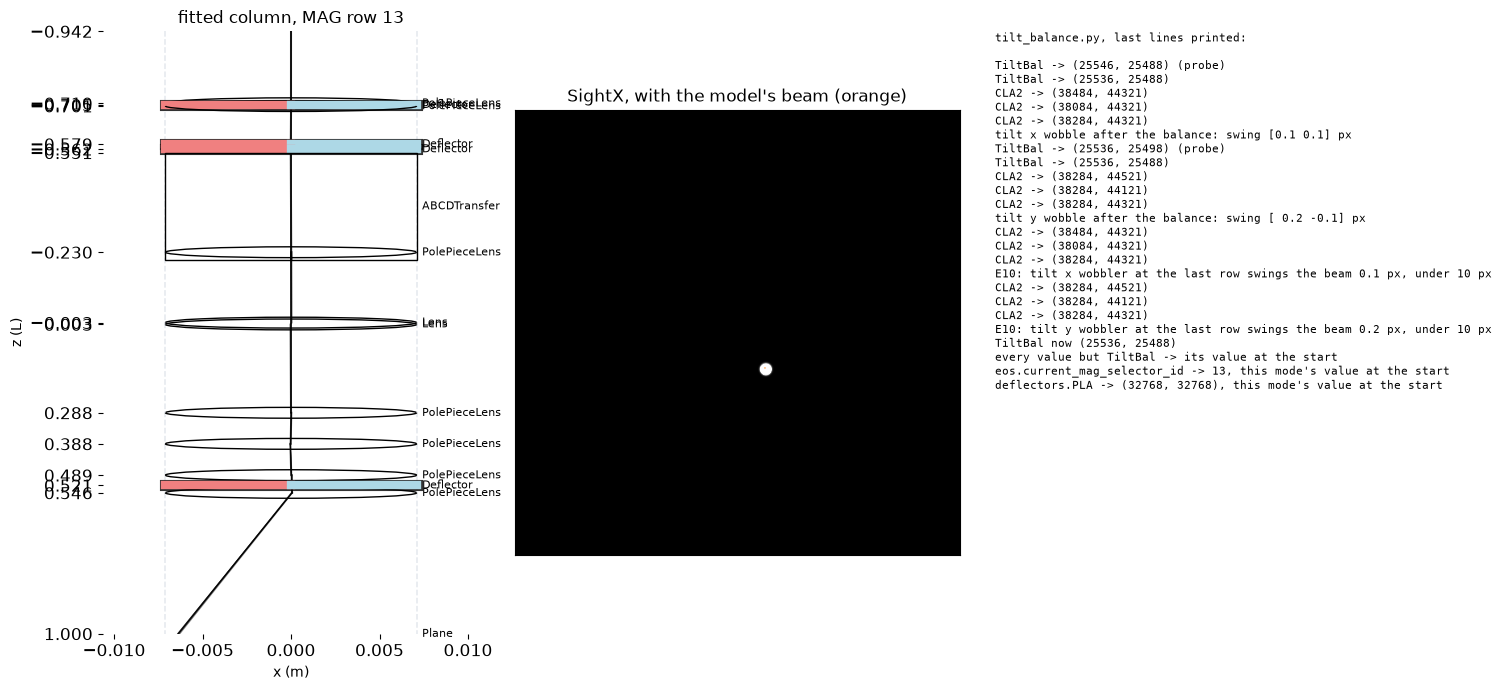

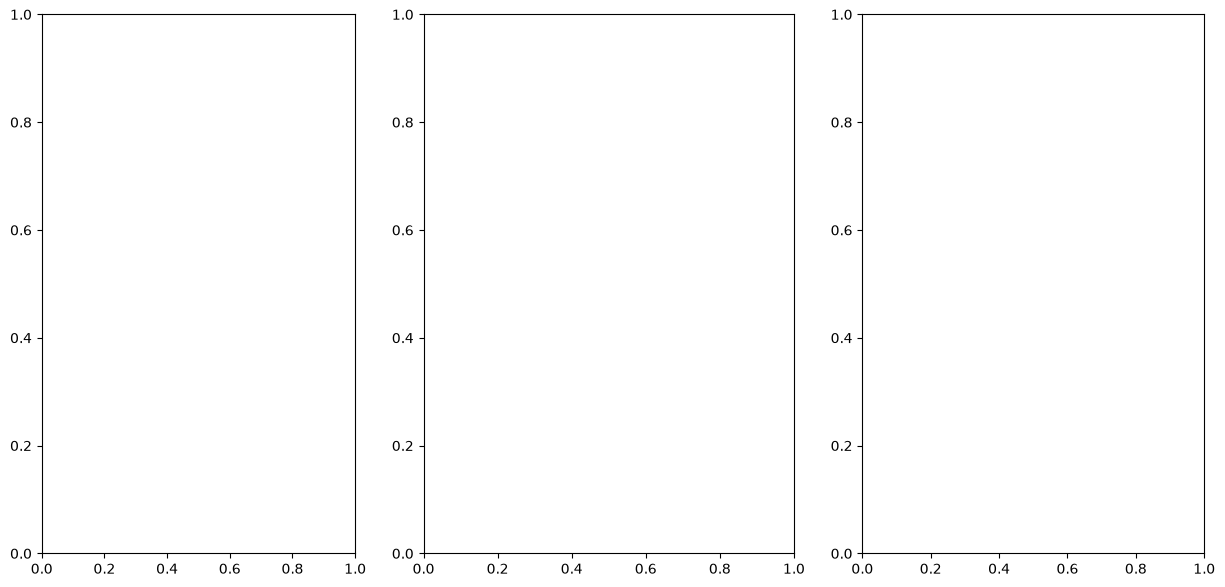

In [3]:
display(Code(filename=SCRIPT, language="python"))
# The script's names, the monitor among them, go to `script`, and what it prints to `printed`.
script = {"__file__": str(HERE / SCRIPT), "__name__": "__main__"}
printed = io.StringIO()
fan_angles = np.linspace(-1, 1, 11) * float(jnp.exp(fitted["spread"]))
fan = Ray(
    x=jnp.zeros(11),
    y=jnp.zeros(11),
    dx=jnp.asarray(fan_angles),
    dy=jnp.zeros(11),
    z=jnp.full(11, z_drawing["Source"]),
    pathlength=jnp.zeros(11),
    voltage=jnp.full(11, VOLTAGE),
)
fig, (ax_column, ax_detector, ax_text) = plt.subplots(
    1, 3, figsize=(15, 7), gridspec_kw=dict(width_ratios=(1.1, 1.3, 1.2))
)
view = display(fig, display_id=True)


def lens_value(monitor, name):
    """Return the DAC value of a lens now: its free lens control value while that is on."""
    if name in ("CL1", "CL3", "OLf", *PROJECTOR):
        on, dac = read_value(monitor, f"lens.free_lens_control.{name}")
        if on:
            return float(dac)
    return float(read_value(monitor, f"lens.{name}"))


def draw_view(monitor):
    """Read the microscope through ``monitor`` and draw the three panels once."""
    lens_dac = jnp.array(
        [lens_value(monitor, n) for n in ("CL1", "CL3", "CM", *PROJECTOR)]
        + [lens_value(monitor, "OLf") - mag_40k["OLf"]]
        + [1.0] * 8
    )
    deflector_dac = jnp.array(
        [
            np.array(read_value(monitor, f"deflectors.{n}"), float) - np.array(aligned[n], float)
            for n in DEFLECTORS
        ]
    )
    mode = "MAG" if int(read_value(monitor, "eos.function_mode")) == 0 else "DIFF"
    selector = int(read_value(monitor, "eos.current_mag_selector_id"))
    frame = take_frame(monitor)
    centre, radius = beam_on_sightx(fitted, FIXED, CORRECTOR_ON, lens_dac, deflector_dac, MIRROR)

    ax_column.clear()
    plot_model(
        column(fitted, FIXED, CORRECTOR_ON, lens_dac, deflector_dac),
        rays=fan,
        ax=ax_column,
        ray_coordinate="x_rot",
        plot_params=legacy_beam_plot_params(label_fontsize=8),
    )
    ax_column.grid(False)
    ax_column.set(title=f"fitted column, {mode} row {selector}", xlabel="x (m)", ylabel="z (L)")

    ax_detector.clear()
    ax_detector.imshow(frame, cmap="gray")
    predicted = plt.Circle(
        tuple(np.asarray(centre) + FRAME_MIDDLE_PX), float(radius), fill=False, color="tab:orange"
    )
    ax_detector.add_patch(predicted)
    ax_detector.set(title="SightX, with the model's beam (orange)", xticks=[], yticks=[])

    ax_text.clear()
    ax_text.axis("off")
    last_lines = printed.getvalue().splitlines()[-24:]
    ax_text.text(
        0,
        1,
        f"{SCRIPT}, last lines printed:\n\n" + "\n".join(last_lines),
        va="top",
        family="monospace",
        fontsize=8,
    )
    fig.tight_layout()
    view.update(fig)


view_problem = []
script_done = threading.Event()


def keep_drawing():
    """Redraw the view every UPDATE_S seconds until the script ends; save every SAVE_EVERY-th."""
    redraws = 0
    try:
        while not script_done.wait(UPDATE_S):
            if "monitor" not in script:
                continue
            draw_view(script["monitor"])
            if redraws % SAVE_EVERY == 0:
                fig.savefig(HERE / f"figures/alignment_window_{redraws:03d}.png", dpi=80)
            redraws += 1
    except Exception as error:
        view_problem.append(error)

## The run

The view starts in its thread, then the script runs here. When the script ends, or stops on an
error or an interrupt, the view draws once more and stops.

In [4]:
view_thread = threading.Thread(target=keep_drawing)
view_thread.start()
try:
    with contextlib.redirect_stdout(printed):
        exec(compile((HERE / SCRIPT).read_text(), SCRIPT, "exec"), script)
finally:
    script_done.set()
    view_thread.join()
    if "monitor" in script:
        draw_view(script["monitor"])
        fig.savefig(HERE / "figures/alignment_window_end.png", dpi=80)
    display(Pretty(f"{SCRIPT} ended; its last line: {printed.getvalue().splitlines()[-1]}"))
if view_problem:
    raise view_problem[0]

tilt_balance.py ended; its last line: deflectors.PLA -> (32768, 32768), this mode's value at the start